In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import joblib


In [18]:
data=pd.read_csv(r'c:\Users\Sneha\Downloads\option 2.csv.xls')

In [19]:
data.columns = data.columns.str.strip()

In [20]:
data

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [21]:
data.shape

(4269, 13)

In [22]:
data.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='object')

In [23]:
data.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [24]:
data.duplicated().sum()


np.int64(0)

In [25]:
data.drop("loan_id", axis=1, inplace=True)

In [26]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [27]:
data["total_assets"] = (
    data["residential_assets_value"] +
    data["commercial_assets_value"] +
    data["luxury_assets_value"] +
    data["bank_asset_value"]
)

In [28]:
data.drop([
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
], axis=1, inplace=True)


In [29]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,total_assets
0,2,Graduate,No,9600000,29900000,12,778,Approved,50700000
1,0,Not Graduate,Yes,4100000,12200000,8,417,Rejected,17000000
2,3,Graduate,No,9100000,29700000,20,506,Rejected,57700000
3,3,Graduate,No,8200000,30700000,8,467,Rejected,52700000
4,5,Not Graduate,Yes,9800000,24200000,20,382,Rejected,55000000
...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,Rejected,7400000
4265,0,Not Graduate,Yes,3300000,11300000,20,559,Approved,20000000
4266,2,Not Graduate,No,6500000,23900000,18,457,Rejected,39000000
4267,1,Not Graduate,No,4100000,12800000,8,780,Approved,28800000


In [42]:
data["loan_income_ratio"] = data["loan_amount"] / data["income_annum"]

In [39]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,total_assets,loan_income_ratio
0,2,Graduate,No,9600000,29900000,12,778,Approved,50700000,3.114583
1,0,Not Graduate,Yes,4100000,12200000,8,417,Rejected,17000000,2.975610
2,3,Graduate,No,9100000,29700000,20,506,Rejected,57700000,3.263736
3,3,Graduate,No,8200000,30700000,8,467,Rejected,52700000,3.743902
4,5,Not Graduate,Yes,9800000,24200000,20,382,Rejected,55000000,2.469388
...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,Rejected,7400000,2.300000
4265,0,Not Graduate,Yes,3300000,11300000,20,559,Approved,20000000,3.424242
4266,2,Not Graduate,No,6500000,23900000,18,457,Rejected,39000000,3.676923
4267,1,Not Graduate,No,4100000,12800000,8,780,Approved,28800000,3.121951


In [43]:
data["education"] = data["education"].map({" Graduate": 1, " Not Graduate": 0})
data["self_employed"] = data["self_employed"].map({" Yes": 1, " No": 0})
data["loan_status"] = data["loan_status"].map({" Approved": 1, " Rejected": 0})


In [47]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,total_assets,loan_income_ratio,loan_income_percent
0,2,1,0,9600000,29900000,12,778,1,50700000,3.114583,311.458333
1,0,0,1,4100000,12200000,8,417,0,17000000,2.975610,297.560976
2,3,1,0,9100000,29700000,20,506,0,57700000,3.263736,326.373626
3,3,1,0,8200000,30700000,8,467,0,52700000,3.743902,374.390244
4,5,0,1,9800000,24200000,20,382,0,55000000,2.469388,246.938776
...,...,...,...,...,...,...,...,...,...,...,...
4264,5,1,1,1000000,2300000,12,317,0,7400000,2.300000,230.000000
4265,0,0,1,3300000,11300000,20,559,1,20000000,3.424242,342.424242
4266,2,0,0,6500000,23900000,18,457,0,39000000,3.676923,367.692308
4267,1,0,0,4100000,12800000,8,780,1,28800000,3.121951,312.195122


In [55]:
data.drop('loan_income_percent',axis=1)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,total_assets,loan_income_ratio
0,2,1,0,9600000,29900000,12,778,1,50700000,3.114583
1,0,0,1,4100000,12200000,8,417,0,17000000,2.975610
2,3,1,0,9100000,29700000,20,506,0,57700000,3.263736
3,3,1,0,8200000,30700000,8,467,0,52700000,3.743902
4,5,0,1,9800000,24200000,20,382,0,55000000,2.469388
...,...,...,...,...,...,...,...,...,...,...
4264,5,1,1,1000000,2300000,12,317,0,7400000,2.300000
4265,0,0,1,3300000,11300000,20,559,1,20000000,3.424242
4266,2,0,0,6500000,23900000,18,457,0,39000000,3.676923
4267,1,0,0,4100000,12800000,8,780,1,28800000,3.121951


In [56]:
print(data.shape)
print(data.info())
print(data.describe())

(4269, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   no_of_dependents     4269 non-null   int64  
 1   education            4269 non-null   int64  
 2   self_employed        4269 non-null   int64  
 3   income_annum         4269 non-null   int64  
 4   loan_amount          4269 non-null   int64  
 5   loan_term            4269 non-null   int64  
 6   cibil_score          4269 non-null   int64  
 7   loan_status          4269 non-null   int64  
 8   total_assets         4269 non-null   int64  
 9   loan_income_ratio    4269 non-null   float64
 10  loan_income_percent  4269 non-null   float64
dtypes: float64(2), int64(9)
memory usage: 367.0 KB
None
       no_of_dependents    education  self_employed  income_annum  \
count       4269.000000  4269.000000    4269.000000  4.269000e+03   
mean           2.498712     0.502225 

loan_status
1    2656
0    1613
Name: count, dtype: int64


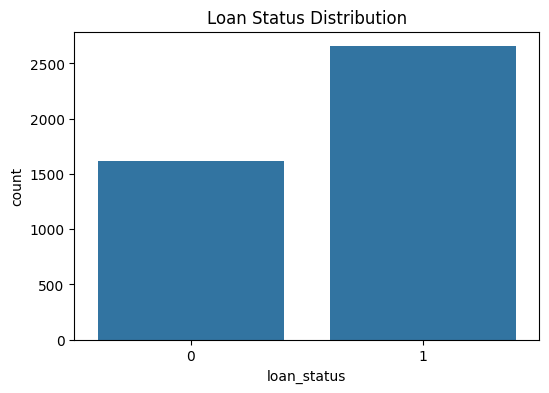

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

print(data["loan_status"].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(x="loan_status", data=data)
plt.title("Loan Status Distribution")
plt.show()

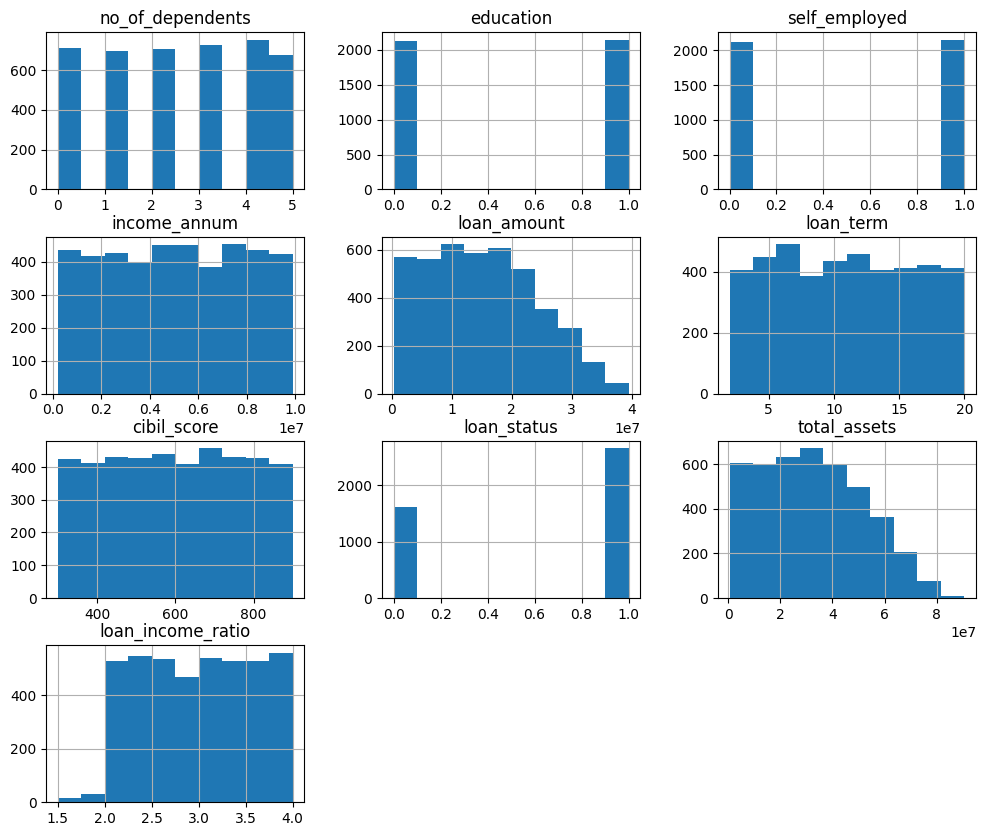

In [60]:
data.hist(figsize=(12,10))
plt.show()

In [59]:
data.drop("loan_income_percent", axis=1, inplace=True)

In [63]:
print(data["cibil_score"].min())
print(data["cibil_score"].max())

300
900


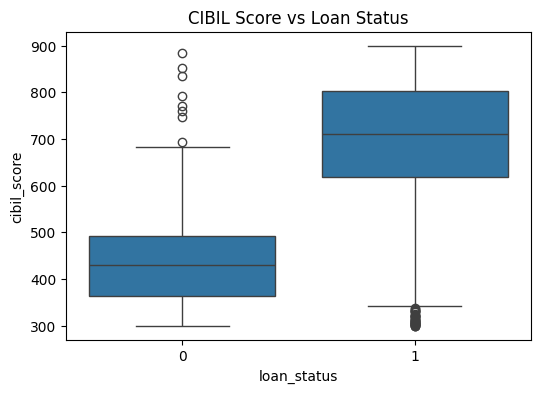

In [64]:
plt.figure(figsize=(6,4))
sns.boxplot(x="loan_status", y="cibil_score", data=data)
plt.title("CIBIL Score vs Loan Status")
plt.show()

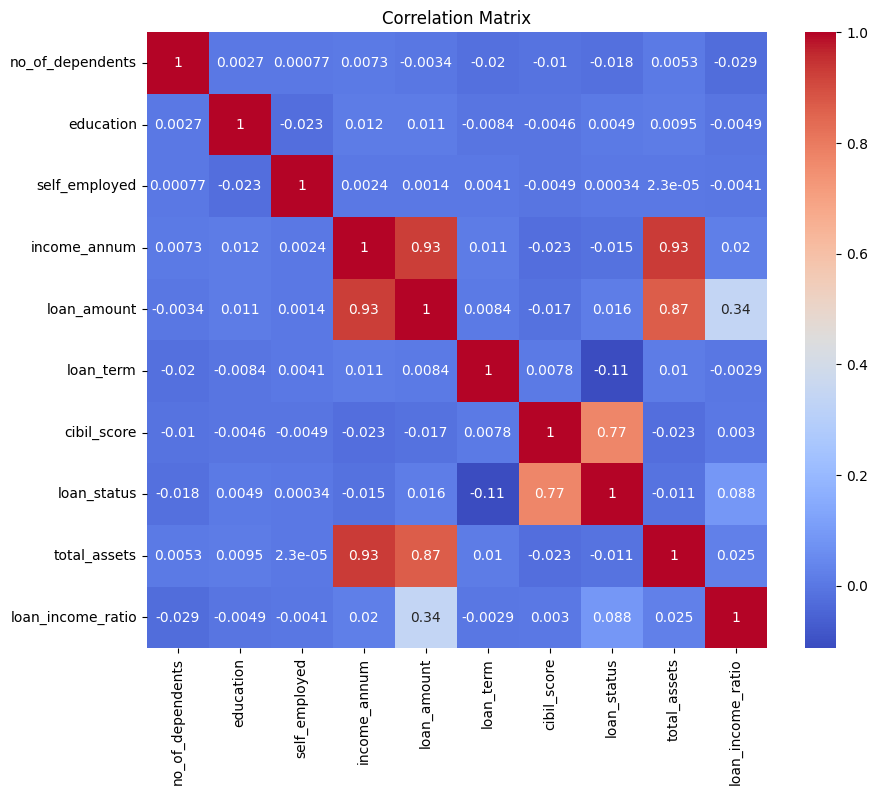

In [66]:
plt.figure(figsize=(10,8))
sns.heatmap(data.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [65]:
print(data.skew())

no_of_dependents    -0.017971
education           -0.008905
self_employed       -0.014529
income_annum        -0.012814
loan_amount          0.308724
loan_term            0.036359
cibil_score         -0.009039
loan_status         -0.504087
total_assets         0.297241
loan_income_ratio   -0.025085
dtype: float64


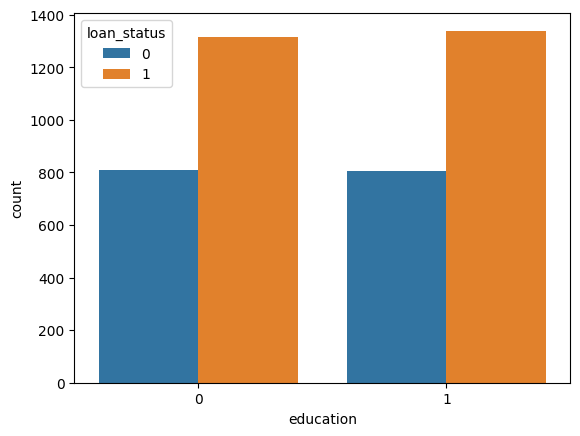

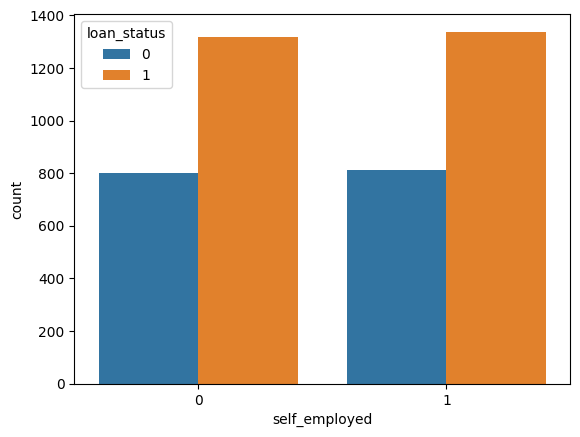

In [69]:
sns.countplot(x="education", hue="loan_status", data=data)
plt.show()

sns.countplot(x="self_employed", hue="loan_status", data=data)
plt.show()

In [71]:
X = data.drop("loan_status", axis=1)
y = data["loan_status"]


In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [75]:
from sklearn.linear_model import LogisticRegression
model =LogisticRegression( max_iter=1000,class_weight="balanced")

In [76]:
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [77]:
y_pred = model.predict(X_test_scaled)

In [78]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9203747072599532

Confusion Matrix:
 [[296  27]
 [ 41 490]]

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.92      0.90       323
           1       0.95      0.92      0.94       531

    accuracy                           0.92       854
   macro avg       0.91      0.92      0.92       854
weighted avg       0.92      0.92      0.92       854



In [79]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42
)

In [80]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [81]:
y_pred = rf_model.predict(X_test)

In [82]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9953161592505855

Confusion Matrix:
 [[319   4]
 [  0 531]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99       323
           1       0.99      1.00      1.00       531

    accuracy                           1.00       854
   macro avg       1.00      0.99      1.00       854
weighted avg       1.00      1.00      1.00       854



In [84]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
print("\nFeature Importance:\n")
print(importances.sort_values(ascending=False))


Feature Importance:

cibil_score          0.818380
loan_term            0.067909
loan_income_ratio    0.054775
loan_amount          0.025055
income_annum         0.019800
no_of_dependents     0.009078
education            0.002568
self_employed        0.002435
dtype: float64


In [86]:
import joblib

# Save Random Forest model
joblib.dump(rf_model, "random_forest_model.pkl")

# Save feature column order
feature_columns = X.columns.tolist()
joblib.dump(feature_columns, "feature_columns.pkl")

print("Model and feature columns saved successfully ✅")

Model and feature columns saved successfully ✅
